# Week 2 - EDA and Preprocessing

**Signal Three | Iranian Churn | Introduction to Machine Learning**

**Ehsan Bali** - dataset overview, missing-value audit, plots 1–2, and train/test preprocessing.  
**Laila Taubay** - plots 3–4 and categorical encoding.  
**Nurzhas Bergenbay** - plots 5–6, outlier assessment, and SMS transformation recommendation.


## Dataset overview - Ehsan

The [UCI Iranian Churn dataset](https://archive.ics.uci.edu/dataset/563/iranian+churn+dataset) contains 3,150 customer records with 13 original input features and one target. The features summarize customer information from the first nine months. The binary target `Churn` records the customer's status at the end of month 12 (0 = stayed, 1 = left). The three intervening months are the planning gap, giving the company time to act on a prediction.

**Hypothesis.** Complaints and call failures will be stronger predictors of churn than age group and tariff plan. We expect complaint status and higher call failures to be associated with more churn.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("./datasets/Customer Churn.csv")
df.columns = df.columns.str.split().str.join(" ")

print("Rows and columns:", df.shape)
print("\nColumn types:\n", df.dtypes.to_string(), sep="")
print("\nSummary statistics:\n", df.describe().T.round(2).to_string(), sep="")

Rows and columns: (3150, 14)

Column types:
Call Failure                 int64
Complains                    int64
Subscription Length          int64
Charge Amount                int64
Seconds of Use               int64
Frequency of use             int64
Frequency of SMS             int64
Distinct Called Numbers      int64
Age Group                    int64
Tariff Plan                  int64
Status                       int64
Age                          int64
Customer Value             float64
Churn                        int64

Summary statistics:
                          count     mean      std   min      25%      50%      75%       max
Call Failure             3150.0     7.63     7.26   0.0     1.00     6.00    12.00     36.00
Complains                3150.0     0.08     0.27   0.0     0.00     0.00     0.00      1.00
Subscription Length      3150.0    32.54     8.57   3.0    30.00    35.00    38.00     47.00
Charge Amount            3150.0     0.94     1.52   0.0     0.00     0.00

The CSV stores counts, durations, and several category codes as integers. `Customer Value` is stored as a decimal. The summary shows wide ranges in usage, so the distribution plots below examine whether those ranges reflect skew or unusually high observations.

## Missing values and class balance - Ehsan

In [2]:
print("Missing values by column:")
print(df.isna().sum().to_string())
class_summary = pd.DataFrame({
    "Customers": df["Churn"].value_counts().sort_index(),
    "Percent": df["Churn"].value_counts(normalize=True).sort_index().mul(100).round(2),
})
print("\nClass distribution:\n", class_summary.to_string(), sep="")

Missing values by column:
Call Failure               0
Complains                  0
Subscription Length        0
Charge Amount              0
Seconds of Use             0
Frequency of use           0
Frequency of SMS           0
Distinct Called Numbers    0
Age Group                  0
Tariff Plan                0
Status                     0
Age                        0
Customer Value             0
Churn                      0

Class distribution:
       Customers  Percent
Churn                    
0           2655    84.29
1            495    15.71


Every column has zero missing values. No rows were removed and no imputation was needed for missing data.

### Plot 1. Churn class count

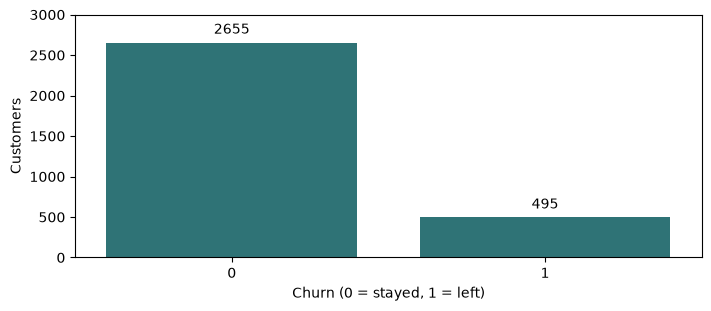

In [3]:
fig, ax = plt.subplots(figsize=(7, 3), layout="constrained")
sns.countplot(data=df, x="Churn", color="#237e82", ax=ax)
ax.bar_label(ax.containers[0], padding=4)
ax.set(xlabel="Churn (0 = stayed, 1 = left)", ylabel="Customers", ylim=(0, 3000))
plt.show()

Of the 3,150 customers, 495 (15.7%) churned. A model that predicts every customer will stay would achieve about 84.3% accuracy, so Week 3 should also compare recall and F1 for the churn class.

## Complaints and churn - Ehsan

### Plot 2. Churn rate by complaint status

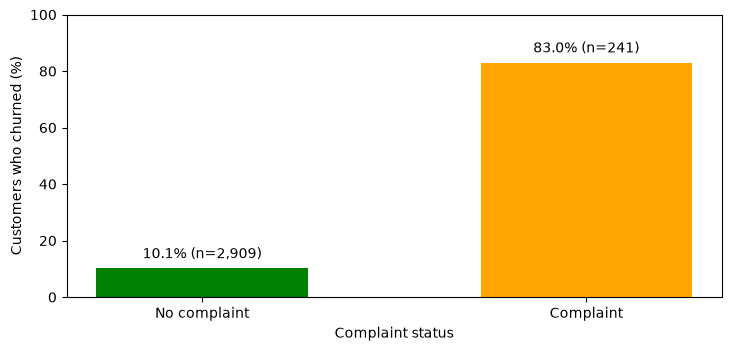

In [4]:
complaint_summary = df.groupby("Complains")["Churn"].agg(["size", "mean"])
complaint_summary["churn_percent"] = 100 * complaint_summary["mean"]

fig, ax = plt.subplots(figsize=(7.2, 3.4), layout="constrained")
bars = ax.bar(["No complaint", "Complaint"], complaint_summary["churn_percent"],
              color=["green", "orange"], width=0.55)
labels = [f"{rate:.1f}% (n={size:,})" for rate, size in
          zip(complaint_summary["churn_percent"], complaint_summary["size"])]
ax.bar_label(bars, labels=labels, padding=5)
ax.set(xlabel="Complaint status", ylabel="Customers who churned (%)", ylim=(0, 100))
plt.show()

Churn was 83.0% among customers with a recorded complaint and 10.1% among those without one. This supports the complaint part of the hypothesis and makes complaint status worth evaluating as a predictor.

## Call failures and correlations - Laila

### Plot 3. Histogram of Call Failure

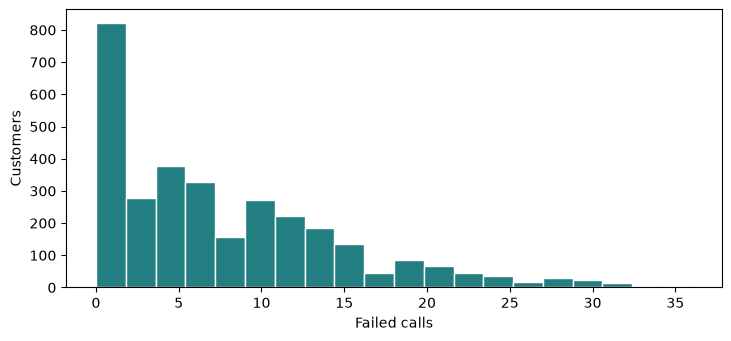

              customers  churn_percent
Call Failure                          
0                   702           19.9
1–2                 258           12.0
3–5                 518           15.8
6–10                756           13.9
11–20               710           13.2
21+                 206           20.9


In [5]:
fig, ax = plt.subplots(figsize=(7.2, 3.3), layout="constrained")
ax.hist(df["Call Failure"], bins=20, color="#237e82", edgecolor="white")
ax.set(xlabel="Failed calls", ylabel="Customers")
plt.show()

failure_ranges = pd.cut(df["Call Failure"], [-1, 0, 2, 5, 10, 20, np.inf],
                        labels=["0", "1–2", "3–5", "6–10", "11–20", "21+"])
rates = df.groupby(failure_ranges, observed=True)["Churn"].agg(["size", "mean"])
rates["churn_percent"] = rates.pop("mean").mul(100).round(1)
print(rates.rename(columns={"size": "customers"}).to_string())

Call failures are right-skewed, with 702 customers recording zero and a median of six. Churn is 19.9% in the zero-failure group, falls to 12.0–15.8% in the middle groups, and rises to 20.9% for 21 or more failures. This pattern gives weak support for the predicted steady increase, so Week 3 will test whether this feature improves prediction.

### Plot 4. Correlation heatmap

Pearson correlations use the original, unscaled columns. For the binary fields, the sign depends on which category has the higher code.

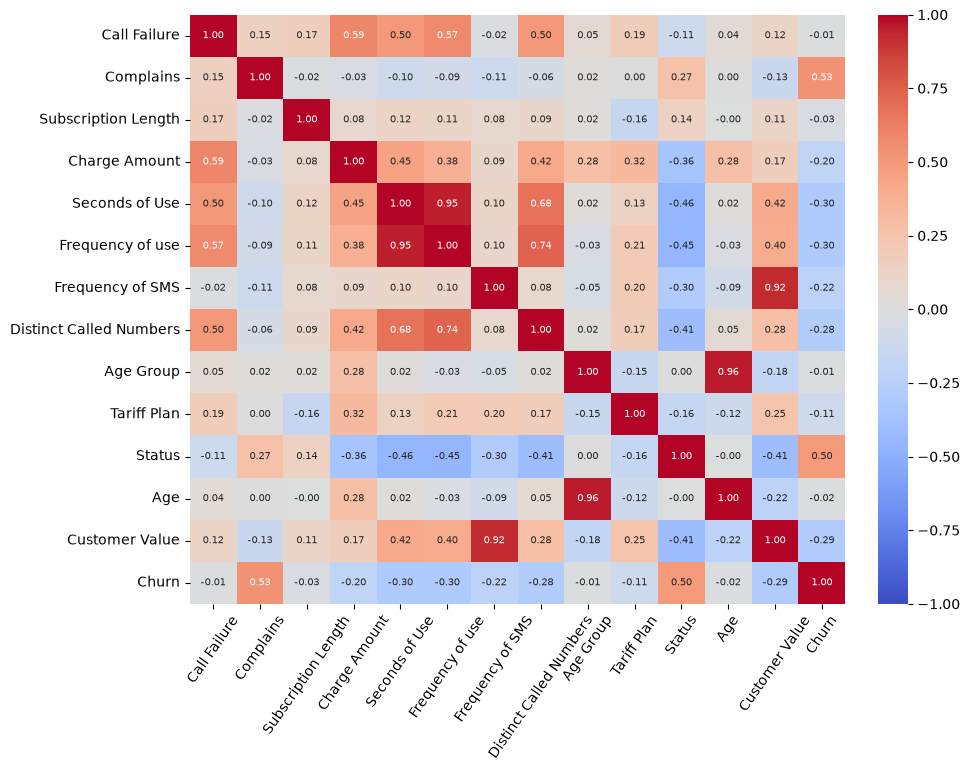

In [6]:
correlations = df.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(9.6, 7.6), layout="constrained")
sns.heatmap(correlations, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, center=0, annot_kws={"fontsize": 7}, ax=ax)
ax.tick_params(axis="x", labelrotation=55)
ax.tick_params(axis="y", labelrotation=0)
plt.show()

Complaints (+0.53) and non-active status (+0.50) have the strongest positive correlations with churn. Frequency of use and total seconds each correlate about −0.30 with churn and about +0.95 with each other, so they capture much of the same usage pattern. Call Failure has a near-zero linear correlation with churn (−0.01), weaker than Tariff Plan (−0.11).

## Usage and outliers - Nurzhas

### Plot 5. Seconds of Use by Churn

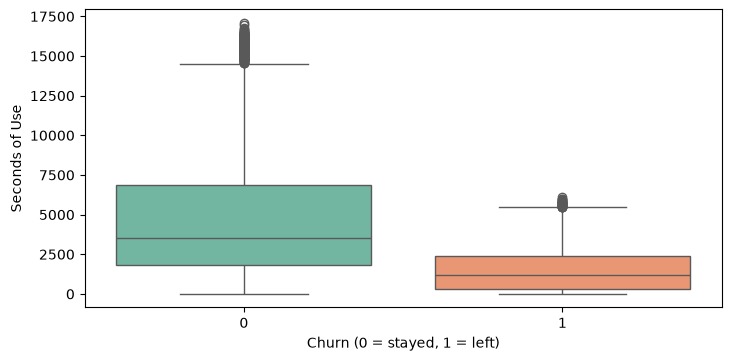

Median seconds by Churn:
Churn
0    3530.0
1    1182.0


In [7]:
fig, ax = plt.subplots(figsize=(7.2, 3.5), layout="constrained")
sns.boxplot(data=df, x="Churn", y="Seconds of Use", hue="Churn",
            palette="Set2", legend=False, ax=ax)
ax.set(xlabel="Churn (0 = stayed, 1 = left)", ylabel="Seconds of Use")
plt.show()
print("Median seconds by Churn:")
print(df.groupby("Churn")["Seconds of Use"].median().to_string())

Customers who stayed had a median of 3,530 seconds of use, versus 1,182 seconds for those who churned. That makes lower total call usage a potential indicator of churn. We kept the high observations because they could be genuine heavy users and the boxplot gives no evidence that those observations are data errors.

### Plot 6. Frequency of SMS histogram

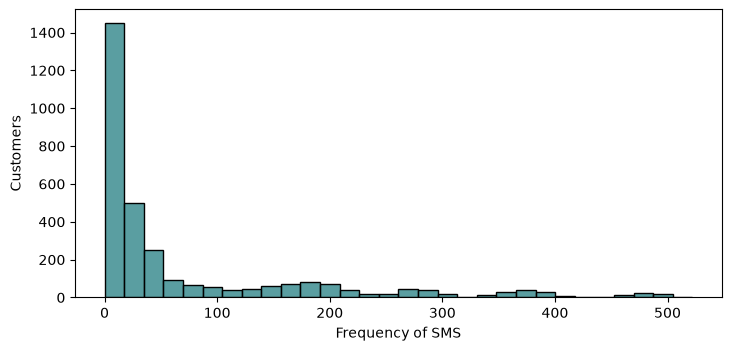

Full dataset SMS skewness: 1.97


In [8]:
fig, ax = plt.subplots(figsize=(7.2, 3.4), layout="constrained")
sns.histplot(data=df, x="Frequency of SMS", bins=30, color="#237e82", ax=ax)
ax.set(xlabel="Frequency of SMS", ylabel="Customers")
plt.show()
print(f"Full dataset SMS skewness: {df['Frequency of SMS'].skew():.2f}")

SMS counts are concentrated at the low end and have a long right tail, with skewness of 1.97. A `log1p` transformation preserves zero counts and compresses the highest values. We check the effect on the training rows before applying the same transformation to both sets.

## Categorical encoding - Laila

`Tariff Plan` and `Status` each have two categories, so one indicator per feature represents both categories for logistic regression, KNN, and decision trees. `Tariff_Contractual` is 1 for contractual plans (original code 2) and 0 for pay-as-you-go plans (code 1). `Status_NonActive` is 1 for non-active status (code 2) and 0 for active status (code 1). The mapping is fixed by the dataset codes and learns nothing from the data.

`Complains` is already binary. `Charge Amount` and `Age Group` remain numeric because their levels are ordered. Following the proposal, we retain `Age Group` and drop `Age`, which is closely related to it.

In [9]:
features = df.drop(columns=["Churn", "Age"]).copy()
features["Tariff_Contractual"] = features.pop("Tariff Plan").map({1: 0, 2: 1})
features["Status_NonActive"] = features.pop("Status").map({1: 0, 2: 1})
binary_columns = ["Complains", "Tariff_Contractual", "Status_NonActive"]
assert features[binary_columns].isin([0, 1]).all().all()

print(features[binary_columns].apply(pd.Series.value_counts).to_string())
print("Features after encoding:", features.shape[1])

   Complains  Tariff_Contractual  Status_NonActive
0       2909                2905              2368
1        241                 245               782
Features after encoding: 12


## Split and numerical preprocessing - Ehsan

The 80/20 split uses a fixed random seed. The test rows stay separate while we check the SMS transformation and fit the scaler. We use `StandardScaler` because KNN relies on distances and the numerical features have different units and ranges. Binary indicators stay at 0/1.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    features, df["Churn"], test_size=0.2, random_state=42
)
X_train, X_test = X_train.copy(), X_test.copy()
sms_column = "Frequency of SMS"
train_sms = X_train[sms_column]
print(f"Training SMS skew: {train_sms.skew():.2f} "
      f"before log1p, {np.log1p(train_sms).skew():.2f} after log1p.")
X_train[sms_column] = np.log1p(train_sms)
X_test[sms_column] = np.log1p(X_test[sms_column])

Training SMS skew: 1.93 before log1p, -0.18 after log1p.


In [11]:
numerical_columns = X_train.select_dtypes(include="number").columns.difference(
    binary_columns, sort=False
)
scaler = StandardScaler()

numeric_types = dict.fromkeys(numerical_columns, "float64")
X_train_scaled = X_train.astype(numeric_types)
X_test_scaled = X_test.astype(numeric_types)
X_train_scaled[numerical_columns] = scaler.fit_transform(X_train[numerical_columns])
X_test_scaled[numerical_columns] = scaler.transform(X_test[numerical_columns])

assert X_train.index.intersection(X_test.index).empty
assert X_train.index.equals(y_train.index) and X_test.index.equals(y_test.index)
assert X_train_scaled[binary_columns].equals(X_train[binary_columns])
assert X_test_scaled[binary_columns].equals(X_test[binary_columns])
print("X_train:", X_train_scaled.shape, "y_train:", y_train.shape)
print("X_test: ", X_test_scaled.shape, "y_test: ", y_test.shape)

X_train: (2520, 12) y_train: (2520,)
X_test:  (630, 12) y_test:  (630,)


The split produced 2,520 training rows and 630 held-out rows, each with 12 features. `fit_transform` learned the scaling statistics from training rows, and `transform` reused those statistics on the test rows. In Week 3, use the unscaled training features with a preprocessing pipeline so each cross-validation fold fits its own scaler. Save the test set for the final model evaluation.